# Classification du type d'anomalie avec MobileNetV2 (DSO 2)
**Jawher.** Suite de **data_preparation.ipynb**. Le modèle dit **quel** est le danger sur la route : animals, obstacles ou cones.

On reprend les leçons du notebook EfficientNet-B0 de Noursine : avec l'image entière, le modèle apprenait le **décor** de chaque photo par cœur.
On utilise donc les mêmes réglages que sa version 2 (recadrage sur l'objet, label smoothing, weight decay, derniers blocs seulement),
pour que la comparaison entre les 3 modèles du DSO 2 soit **équitable**.
MobileNetV2 est le modèle **léger** du DSO 2 : on mesure aussi sa **vitesse**, pour savoir s'il pourrait tourner en temps réel dans une voiture.

## 1. Import

In [3]:
import os, time                                   
import numpy as np                                
import pandas as pd                               
import matplotlib.pyplot as plt                  
from PIL import Image                            
from scipy import ndimage                        
import torch                                      # PyTorch : la bibliothèque de deep learning
import torch.nn as nn                             # couches du réseau (Linear, ReLU, Dropout...) et pertes
from torch.utils.data import Dataset, DataLoader  # Dataset : donne une image ; DataLoader : fait des paquets
from torchvision import models, transforms        # modèles pré-entraînés et transformations d'images
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay   # scores

DOSSIER = r"C:\Users\troud\Desktop\RoadAnomaly"   # dossier principal du projet
if not os.path.isdir(os.path.join(DOSSIER, "frames")):    # si "frames" n'est pas directement dedans...
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")        # ...on descend d'un niveau
PREP = os.path.join(DOSSIER, "frames", "DataPreparation") # données préparées (train / val / test)

torch.manual_seed(42)                                     # même hasard à chaque exécution = résultats reproductibles
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU s'il existe, sinon CPU
print("Appareil :", device)                               # affiche l'appareil utilisé

Appareil : cpu


**Explication :** on importe les bibliothèques et on indique où se trouve `DataPreparation`. `manual_seed(42)` rend les résultats reproductibles, et on utilise le GPU s'il existe.

## 2. Chargement des données

In [6]:
CLASSES = ["animals", "obstacles", "cones"]                         # les 3 classes à prédire
etiquettes = pd.read_csv(f"{PREP}/etiquettes.csv")                  # nom, classe, photo d'origine et ensemble de chaque image
etiquettes["label"] = etiquettes["classe"].map({c: i for i, c in enumerate(CLASSES)})   # classe -> nombre : animals=0, obstacles=1, cones=2

etiquettes["anomalie_%"] = [                                        # % de l'image occupé par l'anomalie
    (np.array(Image.open(f"{PREP}/{e}/masques/{n}.png")) > 0).mean() * 100   # pixels du masque à 1 / tous les pixels
    for n, e in zip(etiquettes.nom, etiquettes.ensemble)            # pour chaque image et son ensemble
]
print(etiquettes.groupby("classe")["anomalie_%"].mean().round(1))   # taille moyenne de l'anomalie par classe
print("Photos d'origine par ensemble :")
print(etiquettes.groupby("ensemble")["source"].nunique())           # nombre de photos d'origine dans train / val / test

classe
animals      12.6
cones         2.8
obstacles     9.5
Name: anomalie_%, dtype: float64
Photos d'origine par ensemble :
ensemble
test      9
train    37
val       8
Name: source, dtype: int64


**Explication :** on lit `etiquettes.csv` (classe, photo d'origine et ensemble de chaque image) et on transforme la classe en nombre. On mesure aussi la part de l'image occupée par l'anomalie : seulement 3 à 13 %. Le reste est du décor, c'est pourquoi on recadre ensuite sur l'objet.

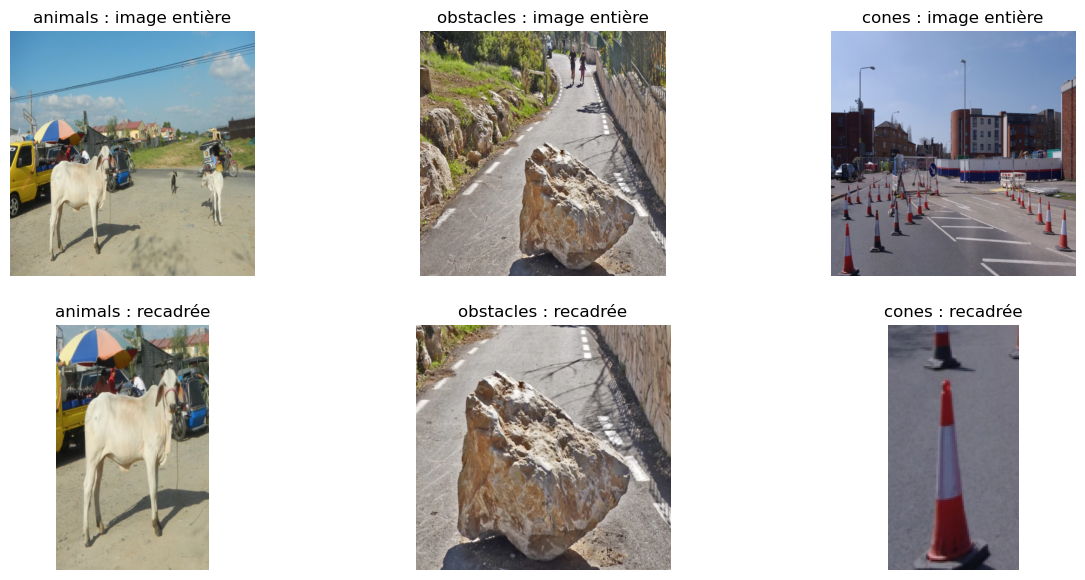

In [8]:
def recadrer(nom, ensemble, marge=0.2):                              # découpe l'image autour de l'anomalie
    img = Image.open(f"{PREP}/{ensemble}/images/{nom}.png").convert("RGB")       # image en couleur
    masque = np.array(Image.open(f"{PREP}/{ensemble}/masques/{nom}.png")) > 0    # masque : True = anomalie
    objets, n = ndimage.label(masque)                                # donne un numéro à chaque objet séparé ; n = nombre d'objets
    if n == 0:                                                       # aucun objet dans le masque...
        return img                                                   # ...on garde l'image entière
    tailles = ndimage.sum(masque, objets, range(1, n + 1))           # taille (en pixels) de chaque objet
    ys, xs = np.where(objets == np.argmax(tailles) + 1)              # coordonnées des pixels du plus grand objet
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()          # rectangle qui entoure cet objet
    dx, dy = int((x1 - x0) * marge) + 10, int((y1 - y0) * marge) + 10   # marge de 20 % (+ 10 pixels) autour
    return img.crop((max(x0 - dx, 0), max(y0 - dy, 0), min(x1 + dx, img.width), min(y1 + dy, img.height)))   # découpe sans sortir de l'image

fig, ax = plt.subplots(2, 3, figsize=(15, 7))                        # grille 2 lignes x 3 colonnes
for i, c in enumerate(CLASSES):                                      # une colonne par classe
    ligne = etiquettes[(etiquettes.classe == c) & (etiquettes.ensemble == "train")].iloc[0]   # première image train de la classe
    ax[0, i].imshow(Image.open(f"{PREP}/train/images/{ligne.nom}.png")); ax[0, i].set_title(f"{c} : image entière")   # en haut : image entière
    ax[1, i].imshow(recadrer(ligne.nom, "train")); ax[1, i].set_title(f"{c} : recadrée")                                # en bas : image recadrée
    ax[0, i].axis("off"); ax[1, i].axis("off")                       # cache les axes
plt.show()

**Explication :** `recadrer` sépare les objets du masque, garde le plus grand, et découpe l'image autour avec 20 % de marge. Le modèle voit l'objet et presque plus le décor. Dans le système final, ce masque viendra du modèle de segmentation du DSO 1.

In [10]:
NORMALISATION = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # moyenne / écart-type ImageNet (R, G, B)

transformation_train = transforms.Compose([                  # transformations du train (avec hasard)
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),       # zoom au hasard (70 à 100 %) puis 224 x 224
    transforms.RandomHorizontalFlip(),                         # retourne l'image au hasard (1 fois sur 2)
    transforms.ColorJitter(0.3, 0.3, 0.3),                     # lumière / contraste / couleurs au hasard
    transforms.ToTensor(),                                     # image -> tenseur, pixels 0..255 -> 0..1
    NORMALISATION,                                             # normalisation ImageNet
])
transformation = transforms.Compose([                         # validation et test : pas de hasard
    transforms.Resize((224, 224)),                             # taille attendue par EfficientNet-B0
    transforms.ToTensor(),                                     # image -> tenseur 0..1
    NORMALISATION,                                             # normalisation ImageNet
])

class RoadDataset(Dataset):                                    # explique à PyTorch comment lire nos images
    def __init__(self, ensemble):                              # ensemble = "train", "val" ou "test"
        self.ensemble = ensemble
        self.df = etiquettes[etiquettes.ensemble == ensemble].reset_index(drop=True)   # lignes de cet ensemble seulement
        self.t = transformation_train if ensemble == "train" else transformation       # hasard seulement pour le train
    def __len__(self):                                         # nombre d'images de l'ensemble
        return len(self.df)
    def __getitem__(self, i):                                  # renvoie l'image n° i et sa classe
        ligne = self.df.iloc[i]
        return self.t(recadrer(ligne.nom, self.ensemble)), ligne.label   # recadrage + transformation, puis le label

train_ds, val_ds, test_ds = RoadDataset("train"), RoadDataset("val"), RoadDataset("test")   # les 3 ensembles
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)  # paquets de 32, mélangés à chaque époque
val_dl = DataLoader(val_ds, batch_size=32)                    # paquets de 32, toujours dans le même ordre
test_dl = DataLoader(test_ds, batch_size=32)
print(len(train_ds), "images train,", len(val_ds), "val,", len(test_ds), "test")   # vérifie le nombre d'images

698 images train, 139 val, 163 test


**Explication :** chaque image est recadrée, mise en **224 × 224** et normalisée comme ImageNet. Pour le train seulement, on ajoute un peu de hasard à chaque époque (zoom, retournement, couleurs) pour éviter l'apprentissage par cœur. Le `DataLoader` donne les images par paquets de **32**.

## 3. Visualisation

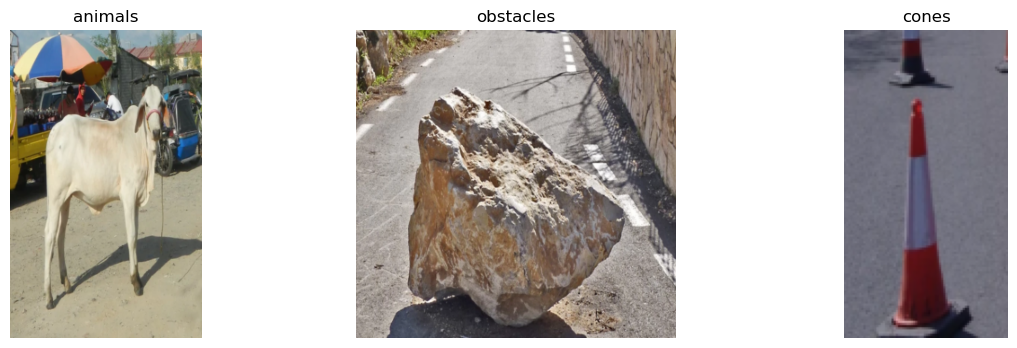

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))                     # 3 images côte à côte
for i, c in enumerate(CLASSES):                                   # une image par classe
    ligne = train_ds.df[train_ds.df.classe == c].iloc[0]          # première image train de la classe
    ax[i].imshow(recadrer(ligne.nom, "train"))                    # image recadrée, telle que le modèle la voit
    ax[i].set_title(c); ax[i].axis("off")
plt.show()

**Explication :** on affiche une image recadrée de chaque classe pour vérifier que l'objet et la classe correspondent.

## 4. Création du modèle

In [16]:
model = models.mobilenet_v2(weights="IMAGENET1K_V1")  # MobileNetV2 déjà entraîné sur ImageNet (transfer learning)
print(model.classifier)                                # tête d'origine : 1280 -> 1000 classes ImageNet

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\troud/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100%|█████████████████████████████████████████████████████████████████████████████| 13.6M/13.6M [00:07<00:00, 1.85MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


**Explication :** on charge MobileNetV2 **pré-entraîné sur ImageNet** (1,2 million d'images) : il sait déjà reconnaître formes et textures. Sa tête `classifier` prédit 1000 classes, il faut la remplacer.

## 5. Remplacer la tête

In [19]:
model.classifier = nn.Sequential(                      # notre tête à la place de l'ancienne
    nn.Linear(1280, 256),   # Fully Connected : 1280 caractéristiques -> 256 neurones
    nn.ReLU(),              # Activation
    nn.Dropout(0.5),        # éteint 50 % des neurones au hasard pendant l'entraînement (contre le surapprentissage)
    nn.Linear(256, 3),      # Output : 3 neurones = 3 classes
)
model = model.to(device)                               # envoie le modèle sur le GPU ou le CPU
print(model)                                           # affiche toute l'architecture

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

**Explication :** on remplace `classifier` par la tête imposée : fully connected 1280 → 256, ReLU, Dropout, puis la sortie à 3 neurones. Le Dropout est à **0,5** au lieu de 0,3 prévu dans le plan, comme pour Noursine et Louay, pour que les 3 modèles aient les mêmes réglages.

## 6. Architecture

In [22]:
couches = pd.Series([type(m).__name__ for m in model.modules()]).value_counts()   # compte chaque type de couche
print(couches.reindex(["Conv2d", "ReLU6", "ReLU", "Linear"]).fillna(0).astype(int))   # convolution, activations, fully connected
print("Paramètres :", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "millions")   # nombre total de poids

Conv2d    52
ReLU6     35
ReLU       1
Linear     2
Name: count, dtype: int32
Paramètres : 2.6 millions


**Explication :** on retrouve l'architecture imposée dans MobileNetV2 :

| Étape imposée | Dans MobileNetV2 |
| --- | --- |
| 1. Convolution | `Conv2d` : conv 3 × 3 au début, puis 17 blocs « inverted residual » (convolutions séparables en profondeur) |
| 2. Activation | `ReLU6` dans le backbone (un ReLU limité à 6), `ReLU` dans notre tête |
| 3. Pooling | convolutions de pas 2 qui réduisent l'image, puis Global Average Pooling à la fin (1280 valeurs). Il est fait dans le code du modèle (`adaptive_avg_pool2d`), c'est pour ça qu'il n'apparaît pas comme une couche dans le compte |
| 4. Fully Connected | `Linear(1280, 256)` + ReLU + Dropout |
| 5. Output | `Linear(256, 3)` + Softmax → probabilité de chaque classe |

Particularité de MobileNetV2 : les **convolutions séparables en profondeur** coupent une convolution en deux petites, ce qui divise le calcul par 8 à 9. D'où seulement 3,5 M de paramètres, contre 24 M pour ResNet-50. Le Softmax est inclus dans la perte `CrossEntropyLoss`.

## 7. Perte et optimiseur

In [25]:
critere = nn.CrossEntropyLoss(label_smoothing=0.1)      # perte de classification ; label smoothing : cible à 90 % au lieu de 100 %

def entrainer_une_epoque(model, dl, optimiseur):         # un passage complet sur le train
    model.train()                                         # mode entraînement (Dropout actif)
    perte_totale, bons = 0, 0
    for x, y in dl:                                       # pour chaque paquet de 32 images
        x, y = x.to(device), y.to(device)                 # images et labels sur le GPU / CPU
        optimiseur.zero_grad()                            # remet les gradients à zéro
        sortie = model(x)                                 # prédiction du modèle (scores des 3 classes)
        perte = critere(sortie, y)                        # erreur entre prédiction et vraie classe
        perte.backward()                                  # calcule les corrections (gradients)
        optimiseur.step()                                 # applique les corrections aux poids
        perte_totale += perte.item() * len(y)             # additionne la perte du paquet
        bons += (sortie.argmax(1) == y).sum().item()      # compte les bonnes réponses
    return perte_totale / len(dl.dataset), bons / len(dl.dataset)   # perte moyenne et accuracy du train

@torch.no_grad()                                          # pas de calcul de gradients : plus rapide, ne modifie rien
def evaluer(model, dl):                                   # mesure le modèle sur val ou test
    model.eval()                                          # mode évaluation (Dropout éteint)
    perte_totale, vrais, preds = 0, [], []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        sortie = model(x)
        perte_totale += critere(sortie, y).item() * len(y)
        preds += sortie.argmax(1).tolist()                # classe prédite = celle avec le plus grand score
        vrais += y.tolist()                               # vraies classes
    return perte_totale / len(dl.dataset), accuracy_score(vrais, preds), f1_score(vrais, preds, average="macro"), vrais, preds   # perte, accuracy, F1 macro, listes

**Explication :** `CrossEntropyLoss` mesure l'erreur de classification ; le **label smoothing** (0,1) demande au modèle d'être sûr à 90 % au lieu de 100 %, donc la perte du train ne descend pas à 0, c'est normal. `entrainer_une_epoque` corrige le modèle sur tout le train ; `evaluer` mesure perte, accuracy et F1 macro sans rien modifier.

## 8. Entraînement 1 : seulement la tête

In [28]:
for p in model.features.parameters():
    p.requires_grad = False                    # backbone gelé : seule notre tête classifier apprend
optimiseur = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=0.01)   # Adam + weight decay (poids gardés petits)

historique = []                                # scores de chaque époque pour les courbes
for epoque in range(5):                        # 5 époques
    perte_train, acc_train = entrainer_une_epoque(model, train_dl, optimiseur)   # apprend sur le train
    perte_val, acc_val, f1_val, _, _ = evaluer(model, val_dl)                     # mesure sur la validation
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "acc_train": acc_train, "acc_val": acc_val, "f1_val": f1_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   accuracy {acc_train:.0%} / {acc_val:.0%}   F1 val {f1_val:.2f}")   # train / validation

Époque 1 : perte 0.542 / 0.464   accuracy 88% / 88%   F1 val 0.87
Époque 2 : perte 0.343 / 0.451   accuracy 100% / 100%   F1 val 1.00
Époque 3 : perte 0.331 / 0.424   accuracy 100% / 99%   F1 val 0.99
Époque 4 : perte 0.333 / 0.432   accuracy 100% / 100%   F1 val 1.00
Époque 5 : perte 0.328 / 0.417   accuracy 100% / 97%   F1 val 0.97


**Explication :** le backbone (`features`) est gelé : seule notre tête apprend pendant 5 époques (lr = 0,001), sans abîmer ce que MobileNetV2 sait déjà. On utilise **AdamW** (Adam + weight decay) pour limiter le surapprentissage.

## 9. Entraînement 2 : derniers blocs + early stopping

In [31]:
for p in model.features[14:].parameters():
    p.requires_grad = True                     # on dégèle aussi les derniers blocs (14 à 18)
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=0.01)   # lr 10 fois plus petit
entrainables = sum(p.numel() for p in model.parameters() if p.requires_grad)   # nombre de poids entraînés
print("Paramètres entraînés :", round(entrainables / 1e6, 1), "millions")

meilleur_f1, attente, PATIENCE = 0, 0, 5      # meilleur score vu ; époques sans progrès ; limite = 5
for epoque in range(30):                       # 30 époques maximum
    perte_train, acc_train = entrainer_une_epoque(model, train_dl, optimiseur)
    perte_val, acc_val, f1_val, _, _ = evaluer(model, val_dl)
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "acc_train": acc_train, "acc_val": acc_val, "f1_val": f1_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   accuracy {acc_train:.0%} / {acc_val:.0%}   F1 val {f1_val:.2f}")
    if f1_val > meilleur_f1:                   # nouveau meilleur F1 de validation ?
        meilleur_f1, attente = f1_val, 0
        torch.save(model.state_dict(), "mobilenetv2_meilleur.pt")   # sauvegarde le meilleur modèle
    else:
        attente += 1                           # une époque de plus sans progrès
        if attente == PATIENCE:                # 5 époques sans progrès : early stopping
            print("Early stopping : le F1 de validation ne progresse plus")
            break
print("Meilleur F1 de validation :", round(meilleur_f1, 3))

Paramètres entraînés : 2.0 millions
Époque 1 : perte 0.318 / 0.414   accuracy 100% / 100%   F1 val 1.00
Époque 2 : perte 0.315 / 0.403   accuracy 100% / 99%   F1 val 0.99
Époque 3 : perte 0.312 / 0.415   accuracy 100% / 98%   F1 val 0.98
Époque 4 : perte 0.312 / 0.422   accuracy 100% / 99%   F1 val 0.99
Époque 5 : perte 0.311 / 0.388   accuracy 100% / 100%   F1 val 1.00
Époque 6 : perte 0.311 / 0.392   accuracy 100% / 100%   F1 val 1.00
Early stopping : le F1 de validation ne progresse plus
Meilleur F1 de validation : 1.0


**Explication :** le plan prévoyait de tout dégeler. Comme pour Noursine et Louay, on dégèle seulement les **derniers blocs** (`features[14:]`, ceux qui reconnaissent les formes complexes), avec un lr 10 fois plus petit. On sauvegarde le modèle chaque fois que le F1 de validation s'améliore, et on arrête après 5 époques sans progrès (**early stopping**).

## 10. Courbes

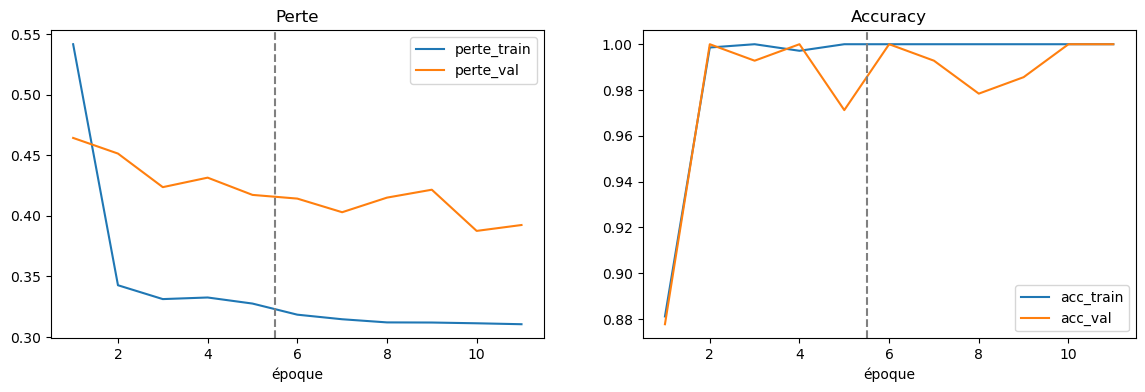

In [34]:
h = pd.DataFrame(historique)                   # scores de toutes les époques dans un tableau
h.index = h.index + 1                          # numéros d'époque à partir de 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4))  # 2 graphiques côte à côte
h[["perte_train", "perte_val"]].plot(ax=ax[0], title="Perte")     # perte train et validation
h[["acc_train", "acc_val"]].plot(ax=ax[1], title="Accuracy")      # accuracy train et validation
for a in ax:
    a.axvline(5.5, color="gray", linestyle="--")    # ligne grise : fin de l'entraînement 1
    a.set_xlabel("époque")
plt.show()

**Explication :** perte et accuracy en train et en validation, la ligne grise sépare les deux entraînements. Pas de surapprentissage si **la perte de validation descend** et si l'écart train / validation reste petit.

## 11. Validation / test

Validation : accuracy = 100.0%   F1 macro = 1.00   photos bien classées = 100% sur 8
Test : accuracy = 93.9%   F1 macro = 0.94   photos bien classées = 89% sur 9
              precision    recall  f1-score   support

     animals       1.00      0.81      0.90        54
   obstacles       0.87      1.00      0.93        67
       cones       1.00      1.00      1.00        42

    accuracy                           0.94       163
   macro avg       0.96      0.94      0.94       163
weighted avg       0.95      0.94      0.94       163



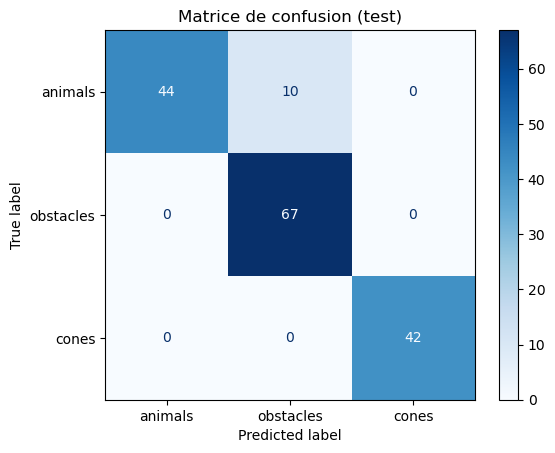

In [37]:
model.load_state_dict(torch.load("mobilenetv2_meilleur.pt", map_location=device))   # recharge le meilleur modèle sauvegardé

def score_par_photo(ds, vrais, preds):                       # score par photo d'origine (vote des copies)
    d = ds.df.assign(vrai=vrais, pred=preds)                 # ajoute vraie classe et prédiction à chaque image
    vote = d.groupby("source").agg(vrai=("vrai", "first"), pred=("pred", lambda p: p.mode()[0]))   # classe la plus votée par photo
    return (vote.vrai == vote.pred).mean(), len(vote)        # % de photos bien classées, nombre de photos

for nom, ds, dl in [("Validation", val_ds, val_dl), ("Test", test_ds, test_dl)]:   # validation puis test
    _, acc, f1, vrais, preds = evaluer(model, dl)
    acc_photo, n_photos = score_par_photo(ds, vrais, preds)
    print(f"{nom} : accuracy = {acc:.1%}   F1 macro = {f1:.2f}   photos bien classées = {acc_photo:.0%} sur {n_photos}")

print(classification_report(vrais, preds, target_names=CLASSES))   # précision, rappel, F1 par classe (test)
ConfusionMatrixDisplay(confusion_matrix(vrais, preds), display_labels=CLASSES).plot(cmap="Blues")   # matrice de confusion du test
plt.title("Matrice de confusion (test)")
plt.show()

**Explication :** on recharge le meilleur modèle et on le mesure sur la validation, puis une seule fois sur le test. Le **score par photo** fait voter les ~20 copies de chaque photo d'origine : c'est plus honnête, car il n'y a que 8 photos en validation et 9 en test. La matrice de confusion montre quelles classes sont confondues. Objectif du DSO 2 : **accuracy ≥ 80 % et F1 macro ≥ 0,75**.

## 12. Vitesse

In [40]:
model.eval()                                            # mode évaluation
x, _ = test_ds[0]                                       # une image du test
x = x.unsqueeze(0).to(device)                           # paquet d'une seule image
with torch.no_grad():
    for _ in range(5):
        model(x)                                        # quelques passages pour « chauffer »
    debut = time.time()
    for _ in range(50):
        model(x)                                        # 50 prédictions
    temps_ms = (time.time() - debut) / 50 * 1000        # temps moyen par image en millisecondes
print(f"Temps par image : {temps_ms:.1f} ms  ->  {1000 / temps_ms:.0f} images par seconde")
print("Paramètres :", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "millions")

Temps par image : 14.5 ms  ->  69 images par seconde
Paramètres : 2.6 millions
